# Plot with channel contributions

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wr_population.paths import FIGURE_DIR, METALLICITIES
from wr_population.io import load_metallicity
from wr_population.classification import (classify_WR, make_binary_mask, formation_channels,
                                          CHANNEL_COLOURS)
from wr_population.plotting import use_posydon_style
use_posydon_style()


In [2]:
labels = ["Stable (S1)", "Stable (S2)", "No MT (S1)", "No MT (S2)",
          "Unstable (S1)", "Unstable (S2)", "Reverse Stable (S1)"]

contributions = {}
for metallicity in METALLICITIES:
    d = load_metallicity(metallicity)
    WNL, WNE, WC = classify_WR(d)
    WR = (WNL | WNE | WC) & make_binary_mask(d)
    channel = formation_channels(d, metallicity)[WR]
    weights = d['weight'][WR] * d['model_weight'][WR]
    del d

    channel_weights = pd.Series(weights).groupby(channel).sum().reindex(labels + ['Other'], fill_value=0.0)
    contributions[metallicity] = 100 * channel_weights / channel_weights.sum()
    print(f"Z = {metallicity} Zsun")
    print(contributions[metallicity].round(1).to_string(), '\n')

contributions = pd.DataFrame(contributions).T  # rows: metallicity, columns: channel
metallicities = np.array(contributions.index)
values = contributions[labels].values

Z = 0.01 Zsun
Stable (S1)            35.3
Stable (S2)             4.2
No MT (S1)             33.2
No MT (S2)             14.3
Unstable (S1)           7.9
Unstable (S2)           3.6
Reverse Stable (S1)     1.4
Other                   0.0 



Z = 0.1 Zsun
Stable (S1)            46.6
Stable (S2)            15.7
No MT (S1)             20.7
No MT (S2)              7.3
Unstable (S1)           4.7
Unstable (S2)           4.0
Reverse Stable (S1)     0.8
Other                   0.0 



Z = 0.2 Zsun
Stable (S1)            48.7
Stable (S2)            18.5
No MT (S1)             17.1
No MT (S2)              7.0
Unstable (S1)           2.6
Unstable (S2)           3.8
Reverse Stable (S1)     2.3
Other                   0.0 



Z = 0.45 Zsun
Stable (S1)            45.4
Stable (S2)            18.9
No MT (S1)             16.5
No MT (S2)              9.7
Unstable (S1)           1.7
Unstable (S2)           4.6
Reverse Stable (S1)     3.3
Other                   0.0 



Z = 1.0 Zsun
Stable (S1)            40.6
Stable (S2)            13.6
No MT (S1)             26.8
No MT (S2)             11.0
Unstable (S1)           1.5
Unstable (S2)           3.6
Reverse Stable (S1)     2.9
Other                   0.0 



In [3]:
colours = CHANNEL_COLOURS

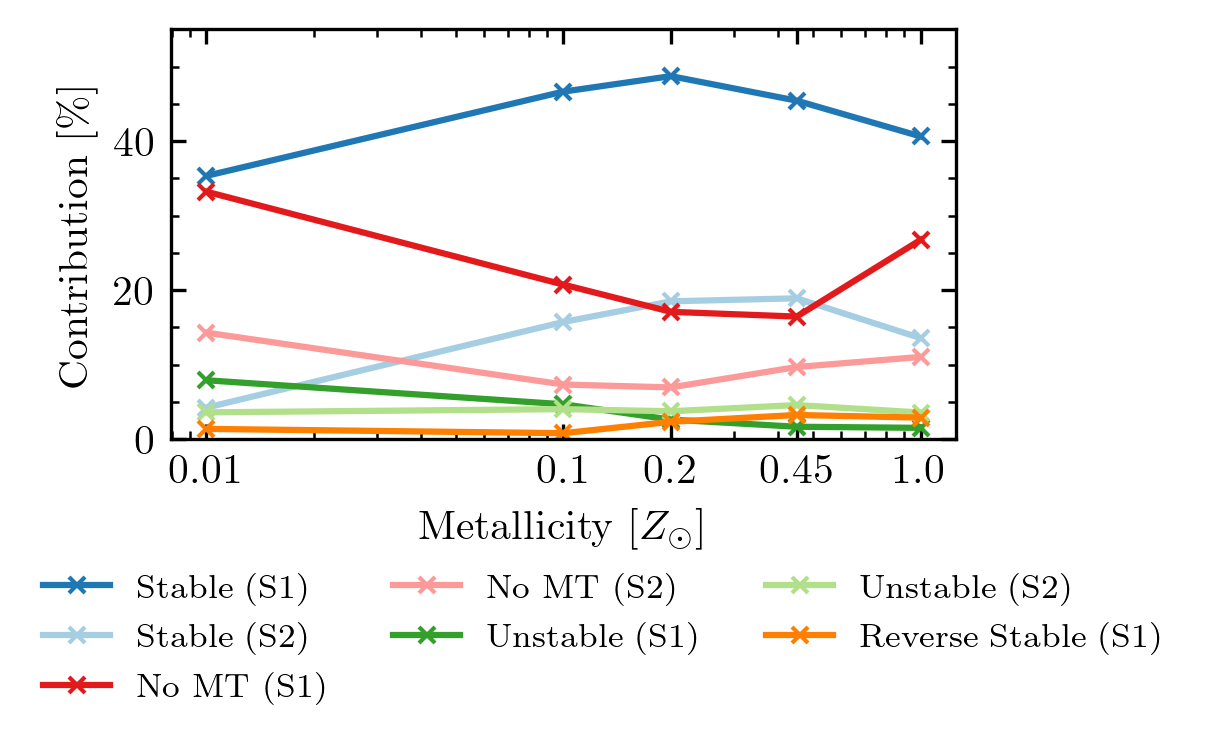

In [4]:

# Line + marker plot (non-stacked)
fig3, ax3 = plt.subplots(1, 1, figsize=(3.38, 2.535*0.7))

for i, label in enumerate(labels):
    ax3.plot(metallicities, values[:, i], marker='x', label=label, color=colours[label])

ax3.set_xlabel('Metallicity [$Z_\\odot$]')
ax3.set_ylabel('Contribution [\%]')
ax3.legend(fontsize=6)

ax3.legend(loc='upper left', bbox_to_anchor=(-0.2, -0.25), ncol=3)
ax3.set_xscale('log')
ax3.set_ylim(0, 55)
ax3.set_xticks(metallicities)
ax3.set_xticklabels(metallicities)


plt.savefig(FIGURE_DIR / 'pdf' / 'relative_contributions.pdf', bbox_inches='tight')
plt.savefig(FIGURE_DIR / 'png' / 'relative_contributions.png', bbox_inches='tight', dpi=300)
